# 02 — EDA and Hypothesis Tests

**AAI-500 Final Team Project, Group 02 — Predicting Credit Card Default**

Names: Abhineet Sood, Ravi Kanth Vuddagiri
Date: October 4, 2026

In notebook 01 we cleaned the data and took a first look. Here we test which variables are actually
related to default:

- **Categorical variables** (sex, education, marital status, age group, repayment status):
  chi-squared test of independence.
- **Sex:** two-proportion z test and a 95% CI for the difference in default rates.
- **Numeric variables** (credit limit, age, bill and payment amounts): two-sample t test with
  `equal_var=False` and a 95% CI for the difference in means.
- **Correlation and VIF**, to find columns that carry the same information before we build models.

We use α = 0.05. With almost 30,000 clients, even tiny differences can come out significant, so for
each test we also look at **how big** the difference is.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_raw, PROCESSED_DIR
from src import cleaning

plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 14,
                     "axes.labelsize": 12, "legend.fontsize": 11})
pd.set_option("display.max_columns", 30)
FIG_DIR = PROJECT_ROOT / "reports" / "figures"

## 1. Load the clean data
Notebook 01 saves `credit_default_clean.csv`. If it isn't there yet, we rebuild it from the raw file.

In [2]:
clean_path = PROCESSED_DIR / "credit_default_clean.csv"
if clean_path.exists():
    df = pd.read_csv(clean_path)
else:
    df = cleaning.clean(load_raw())

labeled = cleaning.add_labels(df)
print("Rows =", df.shape[0], " Columns =", df.shape[1])
print("Default rate =", round(df["DEFAULT"].mean(), 4))

Rows = 29965  Columns = 24
Default rate = 0.2213


## 2. Summary statistics by default status

In [3]:
num_cols = ["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1", "PAY_AMT2"]
summary = df.groupby("DEFAULT")[num_cols].agg(["mean", "median", "std"]).T.round(2)
summary.columns = ["No default", "Default"]
summary

No default    Default
LIMIT_BAL mean     178084.51  129984.57
          median   150000.00   90000.00
          std      131665.89  115258.62
AGE       mean         35.42      35.72
          median       34.00      34.00
          std           9.08       9.70
BILL_AMT1 mean      52058.72   48552.81
          median    23242.00   20209.50
          std       73600.55   73801.17
PAY_AMT1  mean       6315.05    3400.12
          median     2474.00    1641.00
          std       18024.37    9548.02
PAY_AMT2  mean       6648.59    3391.72
          median     2253.00    1542.00
          std       25316.93   11742.85

Clients who defaulted had **lower credit limits** (median NTD 90,000 vs. NTD 150,000) and **paid less**
in the last two months. Age and bill size look almost the same in both groups. For the dollar columns the
mean is much bigger than the median, so these are **skewed right**: a few clients with very large values
pull the mean up.

## 3. Chi-squared tests for the categorical variables
For each variable:

- H₀: the variable and default are independent (the default rate is the same in every group)
- Hₐ: the default rate is different in at least one group

For September repayment status we group the codes into four levels. Codes 3–8 have fewer than 500
clients combined, so they go into "2+ months late". This also keeps every expected count above 5, which
the chi-squared test needs. For age we use five age groups.

In [4]:
from scipy import stats

def sep_status_group(pay1):
    if pay1 <= -1:
        return "Paid / no balance"
    if pay1 == 0:
        return "Revolving"
    if pay1 == 1:
        return "1 month late"
    return "2+ months late"

labeled["SEP_STATUS"] = df["PAY_1"].apply(sep_status_group)
labeled["AGE_GROUP"] = pd.cut(df["AGE"], bins=[20, 30, 40, 50, 60, 80],
                              labels=["21-30", "31-40", "41-50", "51-60", "61+"])

for col in ["SEX", "EDUCATION", "MARRIAGE", "AGE_GROUP", "SEP_STATUS"]:
    table = pd.crosstab(labeled[col], labeled["DEFAULT"])
    chi2 = stats.chi2_contingency(table)
    rates = labeled.groupby(col, observed=True)["DEFAULT"].mean()

    print(col)
    print("  Chi-squared =", round(chi2.statistic, 2), " df =", chi2.dof, " P-value =", chi2.pvalue)
    print("  Smallest expected count =", round(chi2.expected_freq.min(), 2))
    print("  Default rate by group:", rates.round(2).to_dict())
    print("  Gap between highest and lowest rate =", round(rates.max() - rates.min(), 2))
    print()

SEX
  Chi-squared = 47.13  df = 1  P-value = 6.639288761646278e-12
  Smallest expected count = 2627.22
  Default rate by group: {'Female': 0.21, 'Male': 0.24}
  Gap between highest and lowest rate = 0.03

EDUCATION
  Chi-squared = 160.46  df = 3  P-value = 1.458089270856381e-34
  Smallest expected count = 103.55
  Default rate by group: {'Graduate': 0.19, 'High school': 0.25, 'Other': 0.07, 'University': 0.24}
  Gap between highest and lowest rate = 0.18

MARRIAGE
  Chi-squared = 27.49  df = 2  P-value = 1.073731946266748e-06
  Smallest expected count = 83.41
  Default rate by group: {'Married': 0.23, 'Other': 0.24, 'Single': 0.21}
  Gap between highest and lowest rate = 0.03

AGE_GROUP
  Chi-squared = 37.49  df = 4  P-value = 1.4288631846501155e-07
  Smallest expected count = 60.18
  Default rate by group: {'21-30': 0.22, '31-40': 0.2, '41-50': 0.23, '51-60': 0.25, '61+': 0.27}
  Gap between highest and lowest rate = 0.06

SEP_STATUS
  Chi-squared = 5333.29  df = 3  P-value = 0.0
  Sm

All five P-values are below 0.001, so we **reject H₀** for every variable. But the size of the gaps is
very different:

- **September repayment status:** the default rate goes from **0.13** (revolving) to **0.70** (2+ months
  late), a gap of **0.57**. This is a huge difference.
- **Sex, marital status and age group:** the gaps are only about **0.03 to 0.06**. These come out
  significant mostly because the sample is so large.
- **Education:** the gap is 0.18, but that's because of the small "Other" group (468 clients, many with
  undocumented codes). Without it, the rates only go from 0.19 to 0.25.

All the smallest expected counts are well above 5, so the chi-squared test is fine to use here.

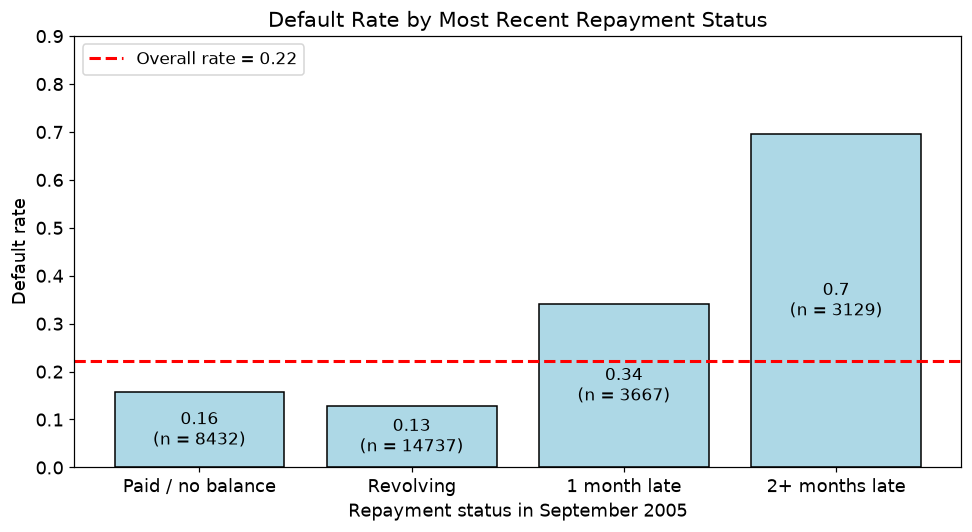

In [5]:
order = ["Paid / no balance", "Revolving", "1 month late", "2+ months late"]
rates = labeled.groupby("SEP_STATUS")["DEFAULT"].agg(["mean", "size"]).loc[order]

plt.figure(figsize=(9, 5))
plt.bar(order, rates["mean"], color="lightblue", edgecolor="black")
for i, (rate, n) in enumerate(rates.values):
    plt.text(i, rate / 2, str(round(rate, 2)) + "\n(n = " + str(int(n)) + ")",
             ha="center", va="center", fontsize=11)
plt.axhline(df["DEFAULT"].mean(), color="red", linestyle="--", linewidth=2,
            label="Overall rate = " + str(round(df["DEFAULT"].mean(), 2)))
plt.ylim(0, 0.9)
plt.xlabel("Repayment status in September 2005")
plt.ylabel("Default rate")
plt.title("Default Rate by Most Recent Repayment Status")
plt.legend(loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / "default_rate_by_sep_status.png", dpi=150)
plt.show()

This is the strongest pattern in the data. Clients who paid in full or carried a normal revolving balance
in September defaulted **13–16%** of the time. One month late raises that to **34%**, and two or more
months late to **70%**.

## 4. Sex: two-proportion z test and 95% CI
Sex is the variable people worry about most for fairness, so we look at the size of the gap directly.

- H₀: π(male) = π(female)
- Hₐ: π(male) ≠ π(female)

In [6]:
from statsmodels.stats.proportion import proportions_ztest

male = df.loc[df["SEX"] == 1, "DEFAULT"]
female = df.loc[df["SEX"] == 2, "DEFAULT"]
z, p_value = proportions_ztest([male.sum(), female.sum()], [len(male), len(female)])

p1 = male.mean()
p2 = female.mean()
diff = p1 - p2
se = np.sqrt(p1 * (1 - p1) / len(male) + p2 * (1 - p2) / len(female))

print("Male default rate =", round(p1, 4), " n =", len(male))
print("Female default rate =", round(p2, 4), " n =", len(female))
print("Difference (male - female) =", round(diff, 4))
print("z =", round(z, 2), " P-value =", p_value)
print("95% CI for the difference:", round(diff - 1.96 * se, 4), "to", round(diff + 1.96 * se, 4))

Male default rate = 0.2416  n = 11874
Female default rate = 0.2079  n = 18091
Difference (male - female) = 0.0337
z = 6.88  P-value = 6.008917036223772e-12
95% CI for the difference: 0.024 to 0.0434


Men defaulted **24.16%** of the time and women **20.79%**. The P-value is basically 0, so the difference
is real. The 95% CI says men default about **2.40 to 4.34 percentage points** more often. That's a small
gap compared with the 20 to 50 point jumps we see with repayment status.

## 5. t tests for the numeric variables
For each numeric column:

- H₀: the mean is the same for clients who defaulted and clients who didn't
- Hₐ: the means are different

We use a two-sample t test with `equal_var=False` (the two groups have different spreads) and report
the 95% CI for the difference (default − no default). The dollar columns are very skewed, so, like we did
with the house prices in Module 4, we also run the same test on log(1 + amount) as a check.

In [7]:
for col in ["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1", "PAY_AMT2"]:
    yes = df.loc[df["DEFAULT"] == 1, col]
    no = df.loc[df["DEFAULT"] == 0, col]
    result = stats.ttest_ind(yes, no, equal_var=False)
    ci = result.confidence_interval(0.95)

    print(col)
    print("  Mean (default) =", round(yes.mean(), 2), " Mean (no default) =", round(no.mean(), 2))
    print("  Difference =", round(yes.mean() - no.mean(), 2))
    print("  t =", round(result.statistic, 2), " P-value =", result.pvalue)
    print("  95% CI for the difference:", round(ci.low, 2), "to", round(ci.high, 2))
    if col != "AGE":
        # a few bills are negative (credits), so we set those to 0 before taking the log
        log_result = stats.ttest_ind(np.log1p(yes.clip(lower=0)), np.log1p(no.clip(lower=0)), equal_var=False)
        print("  Same test on log(1 + amount): P-value =", log_result.pvalue)
    print()

LIMIT_BAL
  Mean (default) = 129984.57  Mean (no default) = 178084.51
  Difference = -48099.94
  t = -29.02  P-value = 4.7916683365578764e-179
  95% CI for the difference: -51348.5 to -44851.38
  Same test on log(1 + amount): P-value = 2.212306212367346e-183

AGE
  Mean (default) = 35.72  Mean (no default) = 35.42
  Difference = 0.3
  t = 2.27  P-value = 0.023050035669612313
  95% CI for the difference: 0.04 to 0.56

BILL_AMT1
  Mean (default) = 48552.81  Mean (no default) = 52058.72
  Difference = -3505.91
  t = -3.42  P-value = 0.0006390717462602051
  95% CI for the difference: -5517.99 to -1493.82
  Same test on log(1 + amount): P-value = 2.495398819242878e-05

PAY_AMT1
  Mean (default) = 3400.12  Mean (no default) = 6315.05
  Difference = -2914.93
  t = -17.52  P-value = 2.971666206918408e-68
  95% CI for the difference: -3240.99 to -2588.87
  Same test on log(1 + amount): P-value = 2.769676056037276e-156

PAY_AMT2
  Mean (default) = 3391.72  Mean (no default) = 6648.59
  Differenc

- **Credit limit:** defaulters had limits about **NTD 48,100 lower** on average. The 95% CI is
  **NTD 44,851 to 51,349 lower**, and the P-value is basically 0.
- **Payments:** defaulters paid about **NTD 2,915 less in September** (95% CI 2,589 to 3,241 less) and
  **NTD 3,257 less in August**. That's roughly **half as much** as non-defaulters.
- **September bill:** defaulters' bills were about NTD 3,506 lower (95% CI 1,494 to 5,518), P = 0.0006.
  That's significant, but it's only about 7% of the average bill, so bill size alone doesn't tell us much.
- **Age:** P = 0.02, so it's significant at α = 0.05. But the difference is only **0.30 years** (95% CI
  **0.04 to 0.56**), which is about 3 to 4 months. That's too small to matter in practice.

The log(1 + amount) checks give the same answers (all P-values close to 0), so the skew doesn't change
our conclusions. Since the samples are very large (6,630 and 23,335), the t test works fine here even
though the amounts aren't normal.

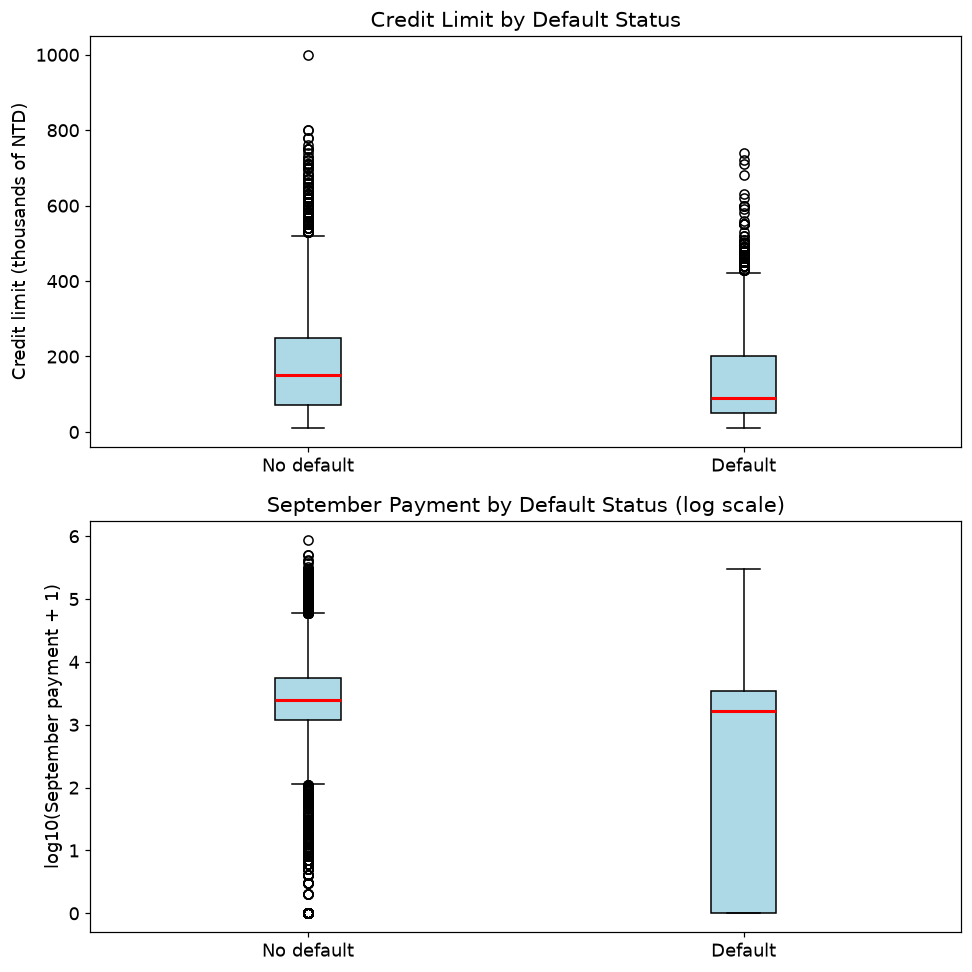

Share who paid 0 in September (default) = 0.28
Share who paid 0 in September (no default) = 0.14


In [8]:
fig, axes = plt.subplots(2, 1, figsize=(9, 9))

limit_no = df.loc[df["DEFAULT"] == 0, "LIMIT_BAL"] / 1000
limit_yes = df.loc[df["DEFAULT"] == 1, "LIMIT_BAL"] / 1000
axes[0].boxplot([limit_no, limit_yes], tick_labels=["No default", "Default"], patch_artist=True,
                boxprops=dict(facecolor="lightblue"), medianprops=dict(color="red", linewidth=2))
axes[0].set_ylabel("Credit limit (thousands of NTD)")
axes[0].set_title("Credit Limit by Default Status")

pay_no = np.log10(df.loc[df["DEFAULT"] == 0, "PAY_AMT1"] + 1)
pay_yes = np.log10(df.loc[df["DEFAULT"] == 1, "PAY_AMT1"] + 1)
axes[1].boxplot([pay_no, pay_yes], tick_labels=["No default", "Default"], patch_artist=True,
                boxprops=dict(facecolor="lightblue"), medianprops=dict(color="red", linewidth=2))
axes[1].set_ylabel("log10(September payment + 1)")
axes[1].set_title("September Payment by Default Status (log scale)")

plt.tight_layout()
plt.savefig(FIG_DIR / "limit_payment_by_default.png", dpi=150)
plt.show()

print("Share who paid 0 in September (default) =", round((df.loc[df["DEFAULT"] == 1, "PAY_AMT1"] == 0).mean(), 2))
print("Share who paid 0 in September (no default) =", round((df.loc[df["DEFAULT"] == 0, "PAY_AMT1"] == 0).mean(), 2))

Both boxplots show what the tests found: the "Default" box sits lower. The payment plot uses a log scale
because payments go from 0 to over NTD 800,000. Without it, the boxes would be squashed at the bottom.
The bottom of the "Default" box reaches 0 because **28% of defaulters paid nothing at all in September**,
compared with 14% of non-defaulters.

## 6. Payment history over six months
So far we only used September. Next we count how many of the six months each client was at least one
month late.

   default_rate  clients
0          0.12    19918
1          0.30     4405
2          0.39     1899
3          0.51     1154
4          0.57      951
5          0.57      298
6          0.70     1340


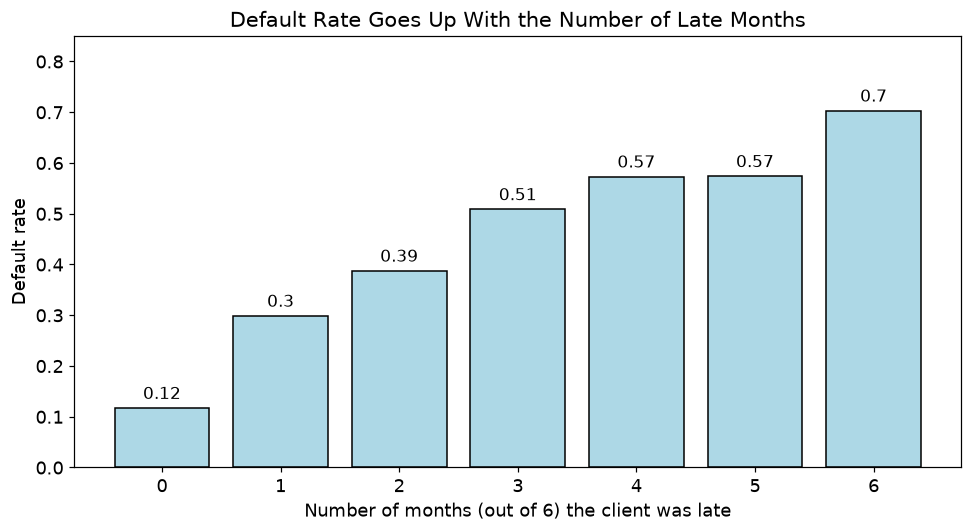

In [9]:
months_late = (df[cleaning.PAY_STATUS_COLS] >= 1).sum(axis=1)
by_count = df.groupby(months_late)["DEFAULT"].agg(["mean", "size"])
by_count.columns = ["default_rate", "clients"]
print(by_count.round(2))

plt.figure(figsize=(9, 5))
plt.bar(by_count.index, by_count["default_rate"], color="lightblue", edgecolor="black")
for x, rate in zip(by_count.index, by_count["default_rate"]):
    plt.text(x, rate + 0.01, str(round(rate, 2)), ha="center", va="bottom", fontsize=11)
plt.xticks(range(7))
plt.ylim(0, 0.85)
plt.xlabel("Number of months (out of 6) the client was late")
plt.ylabel("Default rate")
plt.title("Default Rate Goes Up With the Number of Late Months")
plt.tight_layout()
plt.savefig(FIG_DIR / "default_rate_by_months_late.png", dpi=150)
plt.show()

The default rate goes up almost every step: **0.12** for clients who were never late, **0.30** after one
late month, **0.51** after three, and **0.70** for clients late in all six months. A longer history of late
payments is a strong warning sign, so our models will use both the most recent month and a count of the
earlier late months.

## 7. Correlation between the predictors
If two predictors are very highly correlated, a logistic regression can't tell their effects apart and the
coefficients become unstable. So we check this before modeling.

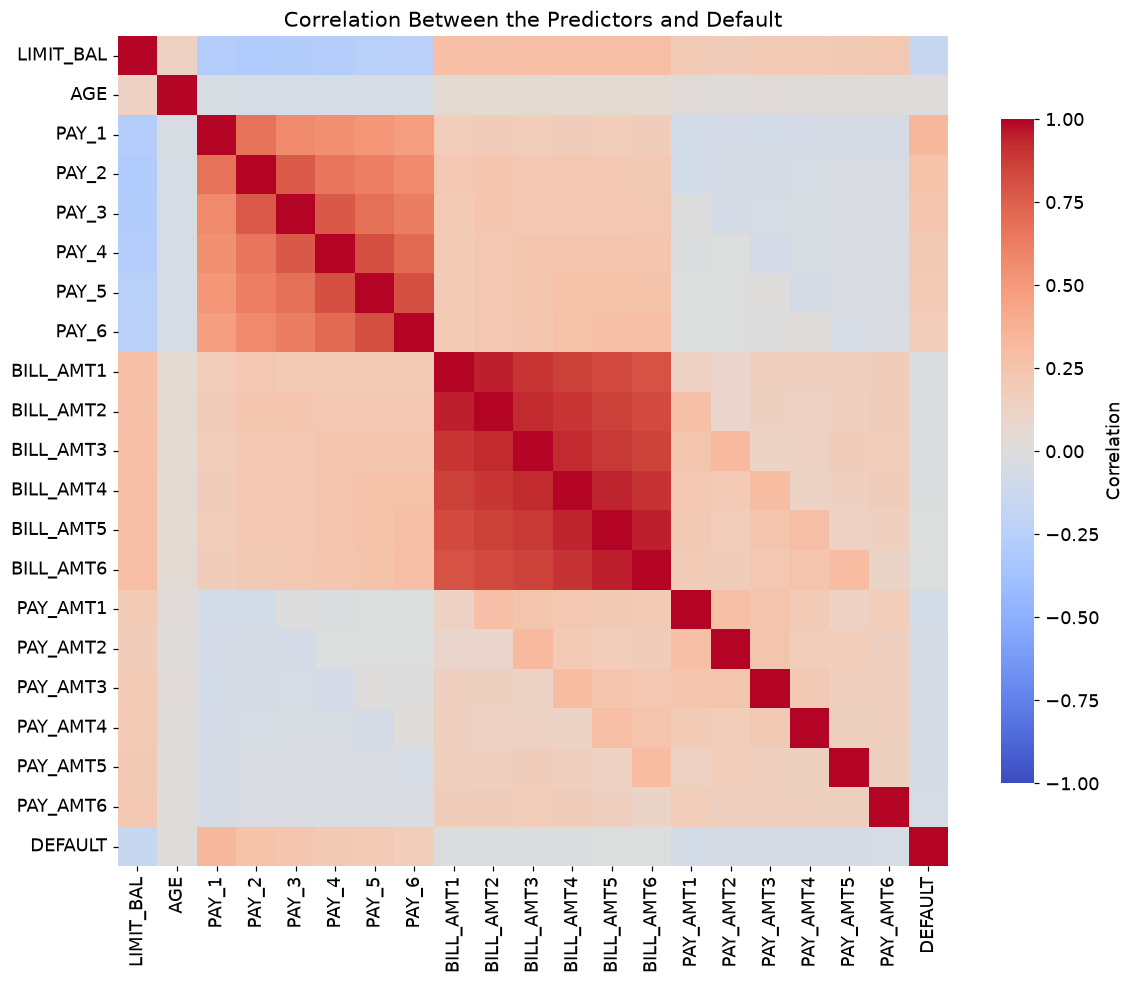

Correlation with DEFAULT:
PAY_1        0.32
PAY_2        0.26
PAY_3        0.24
PAY_4        0.22
PAY_5        0.20
PAY_6        0.19
AGE          0.01
BILL_AMT6   -0.01
BILL_AMT5   -0.01
BILL_AMT4   -0.01
BILL_AMT3   -0.01
BILL_AMT2   -0.01
BILL_AMT1   -0.02
PAY_AMT6    -0.05
PAY_AMT5    -0.06
PAY_AMT3    -0.06
PAY_AMT4    -0.06
PAY_AMT2    -0.06
PAY_AMT1    -0.07
LIMIT_BAL   -0.15


In [10]:
import seaborn as sns

corr_cols = (["LIMIT_BAL", "AGE"] + cleaning.PAY_STATUS_COLS + cleaning.BILL_AMT_COLS
             + cleaning.PAY_AMT_COLS + ["DEFAULT"])
corr = df[corr_cols].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True,
            cbar_kws={"label": "Correlation", "shrink": 0.8})
plt.title("Correlation Between the Predictors and Default")
plt.tight_layout()
plt.savefig(FIG_DIR / "correlation_heatmap.png", dpi=150)
plt.show()

print("Correlation with DEFAULT:")
print(corr["DEFAULT"].drop("DEFAULT").sort_values(ascending=False).round(2).to_string())

Two blocks stand out:

- The six **bill amounts** are very highly correlated with each other (**0.80 to 0.95**). A client's
  balance doesn't change much from month to month.
- The six **repayment status** columns are also correlated (**0.48 to 0.82**).

The columns most correlated with default are the repayment status columns, led by September
(**r = 0.32**). Credit limit has **r = -0.15**: higher limits go with less default.

### Variance inflation factor (VIF) for the bill amounts
VIF shows how much a coefficient's variance is inflated because that column can be predicted from the
other columns. A common rule of thumb is that a VIF above 5 to 10 is a problem.

In [11]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_bill = sm.add_constant(df[cleaning.BILL_AMT_COLS])
for i, col in enumerate(cleaning.BILL_AMT_COLS, start=1):
    print(col, "VIF =", round(variance_inflation_factor(X_bill.values, i), 2))

BILL_AMT1 VIF = 10.65
BILL_AMT2 VIF = 16.01
BILL_AMT3 VIF = 10.75
BILL_AMT4 VIF = 13.28
BILL_AMT5 VIF = 15.69
BILL_AMT6 VIF = 9.7


All six bill columns have VIF around **10 to 16**. If we put all six into a logistic regression, we
couldn't trust their coefficients. In notebook 03 we keep only September's bill, divided by the credit
limit (how much of the limit the client is using).

## 8. Summary

| Variable | Test | Result | How big? |
|---|---|---|---|
| September repayment status | Chi-squared | P ≈ 0 | **Huge** (0.13 → 0.70) |
| Months late (6-month history) | Default rate table | 0.12 → 0.70 | **Huge** |
| Credit limit | t test | P ≈ 0 | About NTD 48,100 lower for defaulters |
| Recent payments | t test | P ≈ 0 | Defaulters paid about half as much |
| Sex | Chi-squared, z test | P ≈ 0 | Small (2.40 to 4.34 points) |
| Education, marital status, age group | Chi-squared | P < 0.001 | Small |
| Age | t test | P = 0.02 | Tiny (0.30 years) |
| Bill amount | t test | P = 0.0006 | Small; highly correlated with other months |

**Takeaway:** how a client has been paying matters much more than who the client is. Next, notebook 03
uses these findings to build a logistic regression and compare it with other models.